# Flight Price Prediction — Random Forest

## How a random forest works (viva notes)

A random forest is an ensemble of decision trees trained with two sources of randomness:

1. **Bootstrap sampling (bagging)**: each tree is trained on a random sample *with replacement* drawn from the training set (~63% unique rows per tree). The remaining ~37% (out-of-bag rows) can be used for internal validation.
2. **Random feature subsets**: at every split, only a random subset of features (`max_features`, default `sqrt(p)`) is considered. This decorrelates the trees — if one feature dominates, not every tree will use it at the top split, so errors don't all point in the same direction.

The final prediction is the **mean** of all tree predictions (regression).

**Why it can beat linear models here:**
- Captures non-linear relationships (e.g. the `days_left` price kink) automatically, without needing engineered features like `last_week`
- Handles interactions between features (e.g. Business + long duration) without explicit cross-terms
- Scale-invariant: splits are based on rank, so StandardScaler is not needed

**Benchmark to beat:** M2 LinearRegression CV RMSE = **$166.75**

In [23]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_predict, RandomizedSearchCV

%matplotlib inline

In [24]:
import copy
from matplotlib.path import Path as MplPath   # alias so it doesn't shadow pathlib.Path

def _path_deepcopy(self, memo=None):
    p = copy.copy(self)
    p._vertices = self._vertices.copy()
    if self._codes is not None:
        p._codes = self._codes.copy()
    p._readonly = False
    return p

MplPath.__deepcopy__ = _path_deepcopy

In [25]:
_cwd = Path().resolve()
ROOT = _cwd if (_cwd / "data").exists() else _cwd.parent
DATA = ROOT / "data"

train = pd.read_csv(DATA / "train.csv")
test  = pd.read_csv(DATA / "test.csv")

# Same cleaning as EDA and 02_modeling
train = train[
    (train['price'] > 0) & (train['airline'] != 'Southern_Airways_Express')
].reset_index(drop=True)

KF = KFold(n_splits=5, shuffle=True, random_state=42)

# Ordinal maps — fixed, not learned
STOPS_MAP = {'zero': 0, 'one': 1, 'two_or_more': 2}
TIME_MAP  = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2,
             'Evening': 3, 'Night': 4, 'Late_Night': 5}
CLASS_MAP = {'Economy': 0, 'Business': 1}

train_enc = train.assign(
    stops          = train['stops'].map(STOPS_MAP),
    departure_time = train['departure_time'].map(TIME_MAP),
    arrival_time   = train['arrival_time'].map(TIME_MAP),
    flight_class   = train['flight_class'].map(CLASS_MAP),
).drop(columns=['id', 'flight'])

# No last_week flag — RF learns the days_left non-linearity on its own
X = train_enc.drop(columns=['price'])
y = train['price'].to_numpy()

print(f"train: {train.shape}   X: {X.shape}")

train: (18050, 12)   X: (18050, 9)


In [26]:
# RF preprocessor: passthrough numeric/ordinal (scale-invariant), OHE categoricals
NUM_COLS = ['duration', 'days_left', 'stops', 'departure_time', 'arrival_time', 'flight_class']
OHE_COLS = ['airline', 'source_city', 'destination_city']

def make_rf_preprocessor():
    return ColumnTransformer([
        ('pass', 'passthrough', NUM_COLS),
        ('ohe',  OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), OHE_COLS),
    ])

def make_rf_pipeline(model):
    return Pipeline([('pre', make_rf_preprocessor()), ('model', model)])

def cv_rmse(model, X, y):
    # 5-fold CV RMSE in original dollar units
    preds = cross_val_predict(model, X, y, cv=KF)
    return float(np.sqrt(np.mean((y - preds) ** 2)))

In [27]:
# RF baseline — sklearn defaults, just to establish where we start
pipe_base = make_rf_pipeline(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
rmse_base = cv_rmse(pipe_base, X, y)
print(f"RF baseline CV RMSE : ${rmse_base:.2f}")
print(f"Best linear (M2)    : $166.75")

RF baseline CV RMSE : $129.03
Best linear (M2)    : $166.75


In [28]:
# Hyperparameter tuning — RandomizedSearchCV
# RandomizedSearchCV samples n_iter random combinations rather than exhaustive grid;
# better than GridSearchCV when the search space is large.
param_dist = {
    'model__n_estimators'    : [100, 200, 300, 500],
    'model__max_depth'       : [None, 10, 20, 30],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__max_features'    : ['sqrt', 'log2', 0.3, 0.5],
}

rs = RandomizedSearchCV(
    make_rf_pipeline(RandomForestRegressor(random_state=42, n_jobs=-1)),
    param_distributions=param_dist,
    n_iter=20,
    cv=KF,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=1,   # outer loop sequential; RF already uses n_jobs=-1 internally
)
rs.fit(X, y)

print("Best params:")
for k, v in rs.best_params_.items():
    print(f"  {k}: {v}")
print(f"\nBest CV RMSE (tuning score): ${-rs.best_score_:.2f}")

Best params:
  model__n_estimators: 100
  model__min_samples_leaf: 2
  model__max_features: 0.5
  model__max_depth: 20

Best CV RMSE (tuning score): $118.84


Best RF CV RMSE : $122.60
Best linear (M2): $166.75   improvement: +44.15


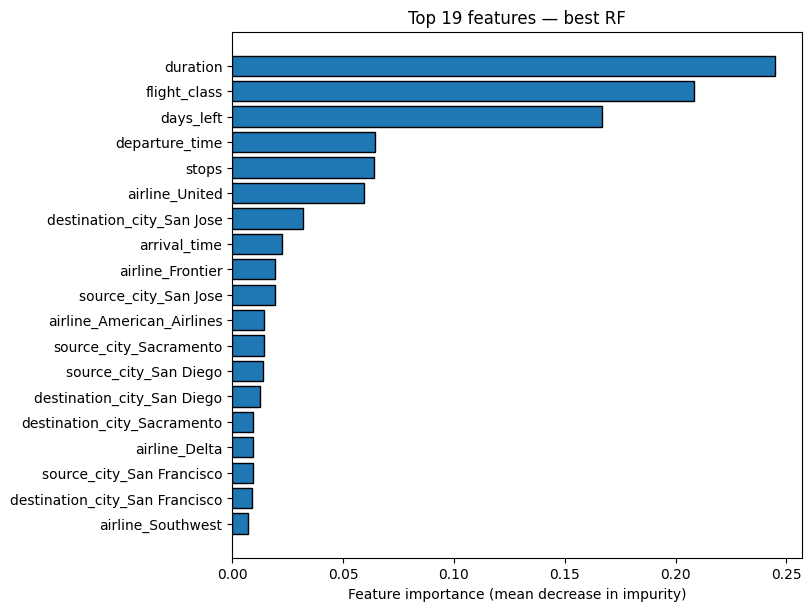

In [29]:
# Best RF — final CV RMSE + feature importance
best_params = {k.replace('model__', ''): v for k, v in rs.best_params_.items()}
pipe_best = make_rf_pipeline(RandomForestRegressor(**best_params, random_state=42, n_jobs=-1))

rmse_best = cv_rmse(pipe_best, X, y)
print(f"Best RF CV RMSE : ${rmse_best:.2f}")
print(f"Best linear (M2): $166.75   improvement: {166.75 - rmse_best:+.2f}")

# Fit on full training set to extract feature importances
pipe_best.fit(X, y)

feature_names = (
    NUM_COLS +
    list(pipe_best.named_steps['pre']
                  .named_transformers_['ohe']
                  .get_feature_names_out(OHE_COLS))
)
importances = pipe_best.named_steps['model'].feature_importances_

top_n = min(20, len(importances))
idx = np.argsort(importances)[-top_n:]

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
ax.barh(range(top_n), importances[idx], edgecolor='black')
ax.set_yticks(range(top_n))
ax.set_yticklabels([feature_names[i] for i in idx])
ax.set_xlabel('Feature importance (mean decrease in impurity)')
ax.set_title(f'Top {top_n} features — best RF')
plt.show()

In [30]:
# Full comparison table
all_results = [
    {'model': 'M1  LinearRegression  numeric only',        'CV RMSE ($)': 207.00},
    {'model': 'M5a Lasso',                                 'CV RMSE ($)': 170.25},
    {'model': 'M5b ElasticNet',                            'CV RMSE ($)': 167.80},
    {'model': 'M4  Ridge  alpha=4.41',                     'CV RMSE ($)': 167.02},
    {'model': 'M3  LinearRegression  log + last_week',     'CV RMSE ($)': 167.01},
    {'model': 'M2  LinearRegression  all features',        'CV RMSE ($)': 166.75},
    {'model': 'RF  baseline (default)',                    'CV RMSE ($)': round(rmse_base, 2)},
    {'model': f'RF  tuned ({best_params})',                'CV RMSE ($)': round(rmse_best, 2)},
]

summary = (pd.DataFrame(all_results)
             .sort_values('CV RMSE ($)')
             .reset_index(drop=True))
summary.index += 1
print(summary.to_string())

                                                                                            model  CV RMSE ($)
1  RF  tuned ({'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 20})       122.60
2                                                                          RF  baseline (default)       129.03
3                                                              M2  LinearRegression  all features       166.75
4                                                           M3  LinearRegression  log + last_week       167.01
5                                                                           M4  Ridge  alpha=4.41       167.02
6                                                                                  M5b ElasticNet       167.80
7                                                                                       M5a Lasso       170.25
8                                                              M1  LinearRegression  numeric only       207.00


In [31]:
# Save the fitted pipeline for submission generation
import pickle

ROOT = Path().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

out_path = ROOT / "outputs" / "model_rf_v1.pkl"
with open(out_path, "wb") as f:
    pickle.dump(pipe_best, f)
print(f"Saved pipeline to {out_path}")

Saved pipeline to /home/dhananjay/dev/ml-project/regression/outputs/model_rf_v1.pkl
